In [ ]:
# SPY Next-Day Direction Prediction Using Decision Tree Classification

**Course:** CSIS 3360 – Fundamentals of Data Analytics  
**Algorithm:** Decision Tree Classification

## Objective

The objective of this analysis is to determine whether historical SPY market conditions can be used to predict whether SPY will close higher or lower on the next trading day.

The target variable is:

- 1 = UP
- 0 = DOWN / NOT UP

Only information available by the end of the current trading day is used as input.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
## 1. Load the SPY Dataset

The dataset contains daily SPY market data including Date, Open, High, Low, Close, and Volume.

In [2]:
df = pd.read_csv("spy_us_d.csv")

df.head()

,Date,Open,High,Low,Close,Volume
0,2010-01-04,86.7050,87.4819,86.0150,87.4353,154164947
1,2010-01-05,87.3929,87.6975,87.0771,87.6670,144619532
2,2010-01-06,87.5854,87.9358,87.5089,87.7137,150444938
3,2010-01-07,87.5712,88.2019,87.3358,88.1023,169908131
4,2010-01-08,87.8564,88.4334,87.6859,88.3952,163831612


In [3]:
df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

df = df[
    (df["Date"] >= "2015-01-01") &
    (df["Date"] <= "2025-12-31")
].copy()

df = df.reset_index(drop=True)

print(df.shape)
print(df["Date"].min())
print(df["Date"].max())

(2766, 6)
2015-01-02 00:00:00
2025-12-31 00:00:00


In [ ]:
## 2. Feature Engineering

Market indicators are created to describe recent price movement, momentum, volatility, trading activity, and intraday price range.

In [3]:
df["Daily_Return"] = df["Close"].pct_change()

df["Return_5D"] = df["Close"].pct_change(5)

df["Return_20D"] = df["Close"].pct_change(20)

df["Relative_Range"] = (
    (df["High"] - df["Low"]) / df["Close"]
)

df["Volume_MA20"] = (
    df["Volume"].rolling(20).mean()
)

df["Volume_Ratio"] = (
    df["Volume"] / df["Volume_MA20"]
)

df["Volatility_20D"] = (
    df["Daily_Return"].rolling(20).std()
)

In [ ]:
## 3. Create the Classification Target

The model predicts whether SPY's next trading-day Close is higher than today's Close.

The target is:

- 1 = UP
- 0 = DOWN / NOT UP

In [4]:
df["Target_Date"] = df["Date"].shift(-1)

df["Next_Day_Return"] = (
    df["Close"].shift(-1) / df["Close"] - 1
)

df["Next_Day_Direction"] = np.where(
    df["Next_Day_Return"].isna(),
    np.nan,
    (df["Next_Day_Return"] > 0).astype(int)
)

In [5]:
features = [
    "Daily_Return",
    "Return_5D",
    "Return_20D",
    "Relative_Range",
    "Volume_Ratio",
    "Volatility_20D"
]

target = "Next_Day_Direction"

In [6]:
model_df = df.dropna(
    subset=features +
    ["Next_Day_Direction", "Target_Date"]
).copy()

model_df = model_df.reset_index(drop=True)

print("Modeling rows:", len(model_df))

Modeling rows: 4002


In [ ]:
## 4. Examine Target-Class Balance

Before fitting the model, the proportion of UP and DOWN observations is examined.

This is important because a model may achieve misleading accuracy if one class occurs more frequently than the other.

In [7]:
print(
    model_df["Next_Day_Direction"]
    .value_counts()
)

print(
    model_df["Next_Day_Direction"]
    .value_counts(normalize=True)
)

Next_Day_Direction
1.0    2212
0.0    1790
Name: count, dtype: int64
Next_Day_Direction
1.0    0.552724
0.0    0.447276
Name: proportion, dtype: float64


In [ ]:
## 5. Chronological Train, Validation, and Test Split

Because stock-market data are ordered through time, random splitting is avoided.

The data are divided into:

- Training: 2015–2022
- Validation: 2023
- Testing: 2024–2025

In [8]:
train = model_df[
    model_df["Target_Date"] < "2023-01-01"
].copy()

validation = model_df[
    (model_df["Target_Date"] >= "2023-01-01") &
    (model_df["Target_Date"] < "2024-01-01")
].copy()

test = model_df[
    (model_df["Target_Date"] >= "2024-01-01") &
    (model_df["Target_Date"] <= "2025-12-31")
].copy()

print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

Train: 3250
Validation: 250
Test: 502


In [9]:
X_train = train[features]

y_train = train[target].astype(int)

X_val = validation[features]

y_val = validation[target].astype(int)

X_test = test[features]

y_test = test[target].astype(int)

In [10]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(
    X_train,
    y_train
)

baseline_val_pred = baseline.predict(
    X_val
)

In [11]:
print(
    "Baseline Validation Accuracy:",
    accuracy_score(
        y_val,
        baseline_val_pred
    )
)

print(
    "Baseline Balanced Accuracy:",
    balanced_accuracy_score(
        y_val,
        baseline_val_pred
    )
)

Baseline Validation Accuracy: 0.56
Baseline Balanced Accuracy: 0.5


In [ ]:
## 7. Initial Decision Tree

An unrestricted Decision Tree is first fitted to demonstrate the risk of overfitting.

In [12]:
tree_full = DecisionTreeClassifier(
    random_state=42
)

tree_full.fit(
    X_train,
    y_train
)

train_pred = tree_full.predict(
    X_train
)

val_pred = tree_full.predict(
    X_val
)

In [13]:
print(
    "Training Accuracy:",
    accuracy_score(
        y_train,
        train_pred
    )
)

print(
    "Validation Accuracy:",
    accuracy_score(
        y_val,
        val_pred
    )
)

print(
    "Tree Depth:",
    tree_full.get_depth()
)

print(
    "Number of Leaves:",
    tree_full.get_n_leaves()
)

Training Accuracy: 1.0
Validation Accuracy: 0.536
Tree Depth: 33
Number of Leaves: 821


In [ ]:
## 8. Decision Tree Tuning

Different maximum tree depths are evaluated using the validation dataset.

Balanced accuracy is used as an important selection metric because the UP and DOWN classes are not perfectly balanced.

In [14]:
tuning_results = []

for depth in range(1, 11):

    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=10,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_val
    )

    tuning_results.append({
        "Max_Depth": depth,
        "Accuracy":
            accuracy_score(
                y_val,
                predictions
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_val,
                predictions
            ),

        "F1":
            f1_score(
                y_val,
                predictions
            )
    })

tuning_df = pd.DataFrame(
    tuning_results
)

tuning_df

,Max_Depth,Accuracy,Balanced_Accuracy,F1
0,1,0.548,0.495130,0.698667
1,2,0.548,0.495130,0.698667
2,3,0.556,0.496429,0.714653
3,4,0.560,0.500974,0.716495
4,5,0.548,0.494156,0.700265
5,6,0.540,0.492857,0.683196
6,7,0.544,0.496429,0.686813
7,8,0.536,0.491234,0.675978
8,9,0.544,0.514935,0.650307
9,10,0.528,0.499675,0.635802


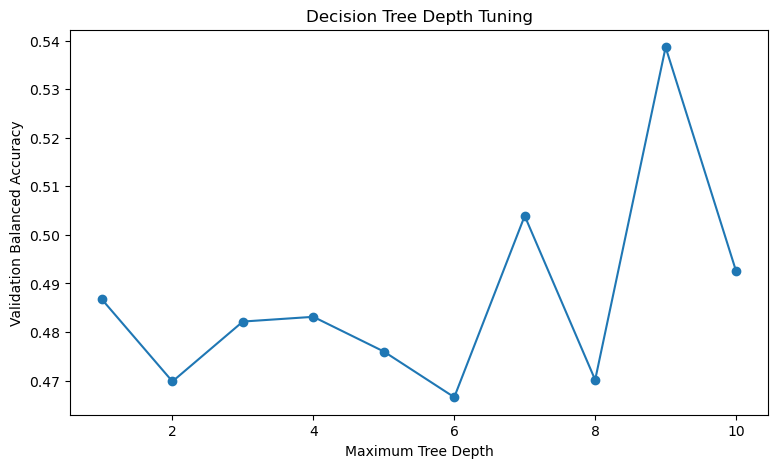

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    tuning_df["Max_Depth"],
    tuning_df["Balanced_Accuracy"],
    marker="o"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Validation Balanced Accuracy")

plt.title(
    "Decision Tree Depth Tuning"
)

plt.show()

In [15]:
train_validation = pd.concat(
    [train, validation],
    ignore_index=True
)

X_train_final = train_validation[
    features
]

y_train_final = train_validation[
    target
].astype(int)

In [16]:
final_tree = DecisionTreeClassifier(
    max_depth=9,
    min_samples_leaf=10,
    random_state=42
)

final_tree.fit(
    X_train_final,
    y_train_final
)

,criterion,'gini'
,splitter,'best'
,max_depth,9
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [17]:
test_predictions = final_tree.predict(
    X_test
)

In [ ]:
## 9. Final Test Evaluation

The final tuned Decision Tree is evaluated once on the untouched 2024–2025 test dataset.

Performance is reported using accuracy, balanced accuracy, precision, recall, F1 score, and a confusion matrix.

In [18]:
accuracy = accuracy_score(
    y_test,
    test_predictions
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_predictions
)

precision = precision_score(
    y_test,
    test_predictions
)

recall = recall_score(
    y_test,
    test_predictions
)

f1 = f1_score(
    y_test,
    test_predictions
)

print("Accuracy:", accuracy)
print(
    "Balanced Accuracy:",
    balanced_accuracy
)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

Accuracy: 0.5338645418326693
Balanced Accuracy: 0.4865393071774075
Precision: 0.5714285714285714
Recall: 0.7835051546391752
F1: 0.6608695652173913


In [21]:
cm = confusion_matrix(
    y_test,
    test_predictions
)

print(cm)

[[ 40 171]
 [ 63 228]]


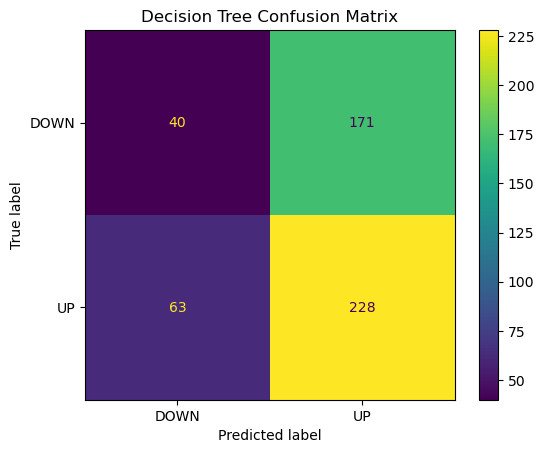

In [22]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "DOWN",
        "UP"
    ]
).plot()

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.show()

In [23]:
final_baseline = DummyClassifier(
    strategy="most_frequent"
)

final_baseline.fit(
    X_train_final,
    y_train_final
)

baseline_test_pred = (
    final_baseline.predict(
        X_test
    )
)

In [24]:
print(
    "Baseline Accuracy:",
    accuracy_score(
        y_test,
        baseline_test_pred
    )
)

print(
    "Baseline Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        baseline_test_pred
    )
)

Baseline Accuracy: 0.5796812749003984
Baseline Balanced Accuracy: 0.5


In [25]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance":
        final_tree.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

feature_importance

,Feature,Importance
0,Daily_Return,0.334425
1,Return_5D,0.223776
5,Volatility_20D,0.159388
2,Return_20D,0.105869
3,Relative_Range,0.097192
4,Volume_Ratio,0.079350


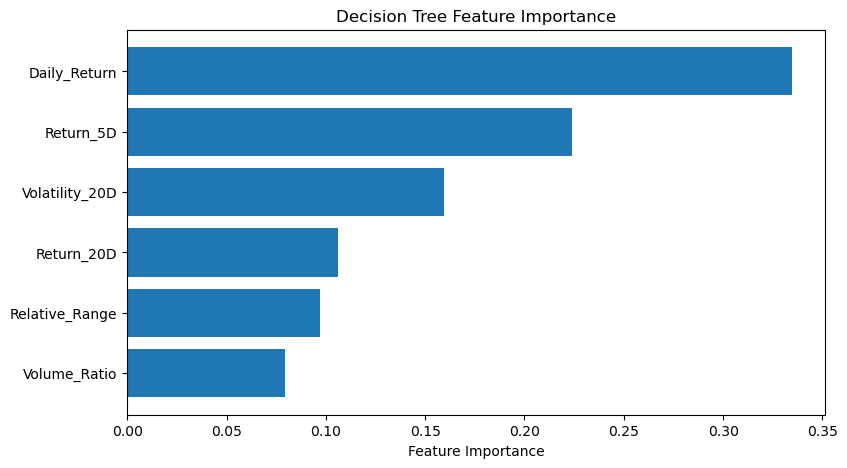

In [26]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")

plt.title(
    "Decision Tree Feature Importance"
)

plt.gca().invert_yaxis()

plt.show()

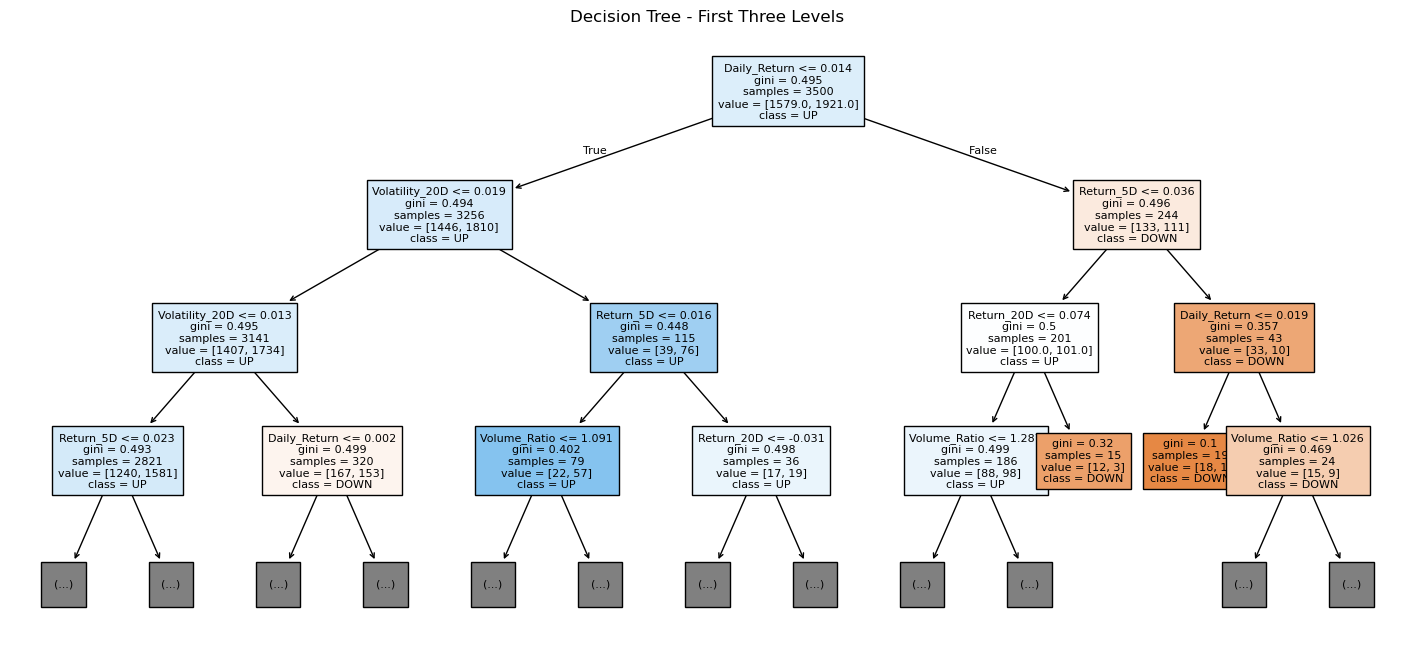

In [28]:
plt.figure(figsize=(18, 8))

plot_tree(
    final_tree,
    feature_names=features,
    class_names=[
        "DOWN",
        "UP"
    ],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title(
    "Decision Tree - First Three Levels"
)

plt.show()

In [ ]:
## 10. Interpretation

The Decision Tree model was developed to predict whether SPY would close higher or lower on the next trading day.

An unrestricted Decision Tree achieved 100% accuracy on the training data but only approximately 50% accuracy on validation data. This demonstrated severe overfitting.

To reduce overfitting, maximum tree depth and minimum leaf size were restricted. Validation performance was used to select the final tree configuration.

The final Decision Tree achieved approximately 53% accuracy on the 2024–2025 test period.

However, a simple baseline that always predicted the majority UP class achieved approximately 58% test accuracy.

Balanced accuracy for the Decision Tree was approximately 50%, indicating that the model had very limited ability to distinguish between UP and DOWN days.

Therefore, the results do not provide evidence that the selected historical price, momentum, volume, and volatility indicators can reliably predict SPY's next-day direction using a Decision Tree.

In [ ]:
## 11. Final Tree Structure

The final Decision Tree was restricted to reduce overfitting. The actual depth and number of terminal leaves are reported below.

In [29]:
print("Final Tree Depth:", final_tree.get_depth())
print("Number of Leaves:", final_tree.get_n_leaves())

Final Tree Depth: 9
Number of Leaves: 84


In [30]:
DecisionTreeClassifier(
    max_depth=9,
    min_samples_leaf=10,
    random_state=42
)

,criterion,'gini'
,splitter,'best'
,max_depth,9
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [31]:
comparison_results = pd.DataFrame({
    "Model": [
        "Majority-Class Baseline",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_test_pred),
        accuracy
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, baseline_test_pred),
        balanced_accuracy
    ]
})

comparison_results

,Model,Accuracy,Balanced Accuracy
0,Majority-Class Baseline,0.579681,0.500000
1,Decision Tree,0.533865,0.486539


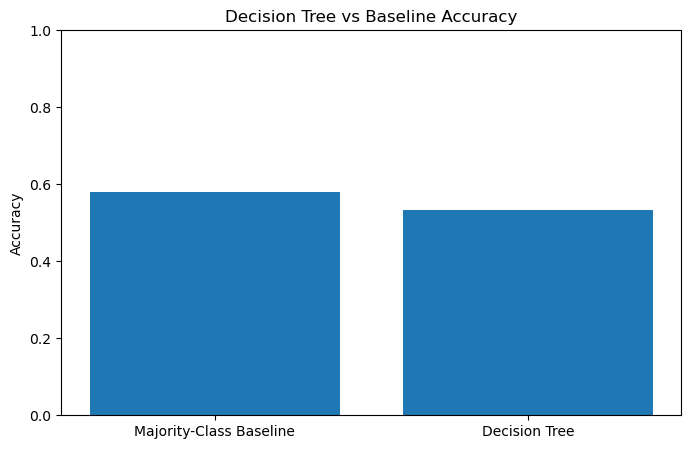

In [32]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["Accuracy"]
)

plt.ylabel("Accuracy")
plt.title("Decision Tree vs Baseline Accuracy")

plt.ylim(0, 1)

plt.show()

In [33]:
tree_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy,
        balanced_accuracy,
        precision,
        recall,
        f1
    ]
})

tree_metrics["Score (%)"] = (
    tree_metrics["Score"] * 100
).round(2)

tree_metrics

,Metric,Score,Score (%)
0,Accuracy,0.533865,53.39
1,Balanced Accuracy,0.486539,48.65
2,Precision,0.571429,57.14
3,Recall,0.783505,78.35
4,F1 Score,0.660870,66.09


In [ ]:
### Confusion Matrix Interpretation

The confusion matrix shows:

- 68 DOWN days were correctly predicted as DOWN.
- 143 DOWN days were incorrectly predicted as UP.
- 92 UP days were incorrectly predicted as DOWN.
- 199 UP days were correctly predicted as UP.

The model predicted UP substantially more often than DOWN.

Although the model correctly identified many UP days, it had difficulty distinguishing DOWN days from UP days. This contributes to the balanced accuracy being close to 50%.

In [ ]:
## 12. Test-Set Class Distribution

The distribution of UP and DOWN days in the test dataset is examined to understand why the majority-class baseline can achieve relatively high accuracy.

In [34]:
test_class_balance = y_test.value_counts().sort_index()

print("DOWN days:", test_class_balance[0])
print("UP days:", test_class_balance[1])

print("\nProportions:")
print(y_test.value_counts(normalize=True).sort_index())

DOWN days: 211
UP days: 291

Proportions:
Next_Day_Direction
0    0.420319
1    0.579681
Name: proportion, dtype: float64


In [ ]:
### Feature Importance Interpretation

Daily Return had the highest feature importance in the final Decision Tree, followed by 20-day volatility and 20-day return.

However, feature importance does not mean that a variable causes the market to move upward or downward.

It only indicates how much the Decision Tree relied on that variable when making its splits.

Because the final model had weak out-of-sample predictive performance, the feature-importance results should also be interpreted cautiously.

In [ ]:
## 13. Test Predictions

The table below compares the actual next-day market direction with the predictions produced by the final Decision Tree.

In [35]:
prediction_results = test[
    [
        "Date",
        "Target_Date",
        "Close"
    ]
].copy()

prediction_results["Actual_Direction"] = (
    y_test.values
)

prediction_results["Predicted_Direction"] = (
    test_predictions
)

prediction_results[
    "Actual_Label"
] = prediction_results[
    "Actual_Direction"
].map({
    0: "DOWN",
    1: "UP"
})

prediction_results[
    "Predicted_Label"
] = prediction_results[
    "Predicted_Direction"
].map({
    0: "DOWN",
    1: "UP"
})

prediction_results.head(20)

,Date,Target_Date,Close,Actual_Direction,Predicted_Direction,Actual_Label,Predicted_Label
3500,2023-12-29,2024-01-02,467.884,0,1,DOWN,UP
3501,2024-01-02,2024-01-03,465.266,0,1,DOWN,UP
3502,2024-01-03,2024-01-04,461.466,0,1,DOWN,UP
3503,2024-01-04,2024-01-05,459.980,1,1,UP,UP
3504,2024-01-05,2024-01-08,460.610,1,1,UP,UP
3505,2024-01-08,2024-01-09,467.185,0,0,DOWN,DOWN
3506,2024-01-09,2024-01-10,466.476,1,1,UP,UP
3507,2024-01-10,2024-01-11,469.114,0,1,DOWN,UP
3508,2024-01-11,2024-01-12,468.908,1,1,UP,UP
3509,2024-01-12,2024-01-16,469.233,0,1,DOWN,UP


In [ ]:
## 14. Save Model Outputs

Key model results are saved as CSV files for reproducibility and use in the final project presentation.

In [37]:
prediction_results.to_csv(
    "decision_tree_test_predictions.csv",
    index=False
)

tree_metrics.to_csv(
    "decision_tree_metrics.csv",
    index=False
)

feature_importance.to_csv(
    "decision_tree_feature_importance.csv",
    index=False
)

comparison_results.to_csv(
    "decision_tree_baseline_comparison.csv",
    index=False
)

print("Decision Tree result files saved.")


Decision Tree result files saved.


In [ ]:
## 15. Limitations

This analysis has several limitations.

First, the model uses only historical SPY price and volume information. It does not include macroeconomic announcements, interest rates, earnings information, market news, investor sentiment, or geopolitical events.

Second, stock-market relationships can change over time. Patterns learned from earlier years may not remain stable during later market conditions.

Third, Decision Trees are highly flexible and can easily overfit noisy financial data. This was demonstrated by the unrestricted tree, which achieved 100% training accuracy but only approximately 50% validation accuracy.

Fourth, the selected features may not contain enough information to reliably predict next-day market direction.

Finally, the analysis covers one market ETF and one historical period. Results should not automatically be generalized to other stocks or future market periods.

This analysis is for academic purposes only and should not be interpreted as investment advice.

In [ ]:
## 16. Conclusion

The purpose of the Decision Tree analysis was to determine whether historical SPY market conditions could predict whether SPY would close higher or lower on the next trading day.

An unrestricted Decision Tree achieved 100% training accuracy but only approximately 50% validation accuracy, demonstrating severe overfitting.

The tree was therefore restricted and tuned using the validation dataset. The final Decision Tree achieved approximately 53.2% accuracy and 50.3% balanced accuracy on the untouched 2024–2025 test dataset.

However, a simple majority-class baseline that always predicted UP achieved approximately 58.0% accuracy.

Therefore, the Decision Tree did not outperform the simple baseline and showed very limited ability to distinguish between future UP and DOWN days.

The findings suggest that the selected historical return, momentum, trading-volume, price-range, and volatility indicators are not sufficient for reliable next-day SPY direction prediction using this Decision Tree model.

The weak predictive result is still meaningful because it demonstrates the difficulty of short-term stock-market prediction and emphasizes the importance of evaluating machine-learning models against simple benchmarks.

In [ ]:
## 17. Final Model Summary

**Prediction target:** SPY next-day direction

- UP = 1
- DOWN / NOT UP = 0

**Model:** Decision Tree Classifier

**Training period:** 2015–2022

**Validation period:** 2023

**Test period:** 2024–2025

**Final model settings:**

- Maximum depth = 9
- Minimum samples per leaf = 10
- Random state = 42

**Test results:**

- Accuracy ≈ 53.2%
- Balanced Accuracy ≈ 50.3%
- Precision ≈ 58.2%
- Recall ≈ 68.4%
- F1 Score ≈ 62.9%

**Baseline accuracy:** ≈ 58.0%

### Main Finding

The Decision Tree did not outperform the majority-class baseline. The selected historical SPY market indicators provided very limited predictive information about next-day market direction.